# K-Nearest Neighbors (KNN)

A complete guide: intuition, mathematics, and implementation from scratch.

## Table of Contents

1. [Intuition](#intuition)
2. [The KNN Algorithm](#algorithm)
3. [Setup & Imports](#imports)
4. [Distance Metrics](#distances)
5. [Implementing Distance Functions](#distance-impl)
6. [Finding the K Nearest Neighbors](#find-knn)
7. [Classification: Majority Vote](#classification-vote)
8. [Regression: Mean of Neighbors](#regression-mean)
9. [Weighted KNN](#weighted-knn)
10. [Complete KNN Implementation](#implementation)
11. [Demo: Classification (Iris)](#classification-demo)
12. [Visualizing Decision Boundaries](#decision-boundary)
13. [Choosing K: Bias-Variance Tradeoff](#choosing-k)
14. [Feature Scaling: Why It Matters](#scaling)
15. [Demo: Regression](#regression-demo)
16. [Curse of Dimensionality](#curse)
17. [Complexity Analysis](#complexity)
18. [Advantages and Disadvantages](#pros-cons)
19. [Summary](#summary)
20. [Sources](#sources)

<a id="intuition"></a>
## 1. Intuition

KNN is based on one of the simplest ideas in machine learning: **similar inputs should produce similar outputs**.

**Real-world analogy — house price estimation:**

You want to estimate the price of a house. You don't build a model. Instead, you look up the 5 most similar houses sold recently (same neighbourhood, similar size, similar rooms) and average their prices. That is KNN.

**Key insight — no explicit training phase.** Most algorithms (decision trees, SVMs, neural nets) build an internal representation during training. KNN does not. It simply stores the entire training set and defers all computation to prediction time. This is called **lazy learning** or **instance-based learning**.

```
Training:    store D = {(x₁,y₁), ..., (xₙ,yₙ)}          O(1)
Prediction:  for a new point x_q:
               1. compute distance to every training point
               2. find K closest ones
               3. aggregate their labels/values
```

**Classification:** the K neighbors vote — majority class wins.

**Regression:** the K neighbors average their target values.

> The algorithm was first described formally by Fix & Hodges (1951) in a technical report, and later analysed theoretically by Cover & Hart (1967) who proved that the error rate of the 1-NN classifier is at most twice the Bayes error rate.

<a id="algorithm"></a>
## 2. The KNN Algorithm

### Formal Definition

Given:
- Training set $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$
- Query point $\mathbf{x}_q \in \mathbb{R}^p$
- Hyperparameter $K \in \{1, 2, \ldots, n\}$
- Distance function $d : \mathbb{R}^p \times \mathbb{R}^p \to \mathbb{R}_{\geq 0}$

**Step 1 — Compute distances:**
$$d_i = d(\mathbf{x}_q, \mathbf{x}_i) \quad \forall i \in \{1,\ldots,n\}$$

**Step 2 — Find K nearest neighbors:**
$$\mathcal{N}_K(\mathbf{x}_q) = \text{argsort}(d_1, d_2, \ldots, d_n)[:K]$$

**Step 3a — Classify** (majority vote):
$$\hat{y} = \underset{c}{\arg\max} \sum_{i \in \mathcal{N}_K(\mathbf{x}_q)} \mathbf{1}[y_i = c]$$

**Step 3b — Regress** (mean):
$$\hat{y} = \frac{1}{K} \sum_{i \in \mathcal{N}_K(\mathbf{x}_q)} y_i$$

### Effect of K

| K | Decision boundary | Bias | Variance |
|---|---|---|---|
| K = 1 | Very jagged, memorizes training data | Low | High |
| K = n | Always predicts global majority/mean | High | Low |
| K optimal | Smooth, generalizes well | Balanced | Balanced |

Rule of thumb: start with $K = \sqrt{n}$ and tune via cross-validation.

<a id="imports"></a>
## 3. Setup & Imports

We use NumPy for all computations and Matplotlib for visualization. scikit-learn is imported only to compare results and load datasets.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from collections import Counter
from sklearn.datasets import load_iris, make_classification, make_regression, make_moons
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
print("Imports OK")

Imports OK


<a id="distances"></a>
## 4. Distance Metrics

The choice of distance function fundamentally shapes which neighbors are "nearest". Different metrics imply different geometries.

### Minkowski Distance (general family)

$$d_r(\mathbf{u}, \mathbf{v}) = \left( \sum_{j=1}^{m} |u_j - v_j|^r \right)^{1/r}$$

Special cases ($m$ = number of features, $r$ = metric order):

| $r$ | Name | Geometry | Unit ball shape |
|---|---|---|---|
| $r = 1$ | **Manhattan** (L1) | City-block distance | Diamond (rotated square) |
| $r = 2$ | **Euclidean** (L2) | Straight-line distance | Circle / Sphere |
| $r \to \infty$ | **Chebyshev** (L∞) | Maximum coordinate difference | Square / Hypercube |

### Cosine Similarity / Distance

Measures the **angle** between vectors, ignoring magnitude. Used in text and high-dimensional data:

$$\text{sim}(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \|\mathbf{v}\|}$$

$$d_{\cos}(\mathbf{u}, \mathbf{v}) = 1 - \text{sim}(\mathbf{u}, \mathbf{v}) \in [0, 2]$$

### Which to Use?

- **Euclidean** — default; works well when features are on similar scales
- **Manhattan** — more robust to outliers; better in high dimensions (less affected by curse of dimensionality)
- **Cosine** — text/NLP, when magnitude is irrelevant (e.g., TF-IDF vectors)
- **Hamming** — categorical / binary features (not implemented here)

<a id="distance-impl"></a>
## 5. Implementing Distance Functions

We implement each metric as a standalone function operating on 1D NumPy vectors, then test them on a concrete pair of 3D points. We also implement a vectorized batch version that computes the distance from one query point to all training points at once.

In [2]:
def euclidean(u, v):
    """L2 distance between vectors u and v."""
    return np.sqrt(np.sum((u - v) ** 2))


def manhattan(u, v):
    """L1 distance (sum of absolute differences)."""
    return np.sum(np.abs(u - v))


def minkowski(u, v, p):
    """Minkowski distance of order p. Reduces to Manhattan (p=1) and Euclidean (p=2)."""
    return np.sum(np.abs(u - v) ** p) ** (1 / p)


def cosine_distance(u, v):
    """1 - cosine similarity. Range [0, 2]. 0 = same direction."""
    denom = np.linalg.norm(u) * np.linalg.norm(v)
    if denom == 0:
        return 0.0
    return 1.0 - np.dot(u, v) / denom


def pairwise_distances(X_query, X_train, metric='euclidean', p=2):
    """
    Compute distance from each query point to every training point.
    Returns array of shape (n_query, n_train).
    
    Uses broadcasting for efficiency: avoids explicit Python loops.
    """
    if metric == 'euclidean':
        # ||u - v||^2 = ||u||^2 + ||v||^2 - 2 u·v  (avoids nested loops)
        sq_query = np.sum(X_query ** 2, axis=1, keepdims=True)   # (n_q, 1)
        sq_train = np.sum(X_train ** 2, axis=1, keepdims=True).T  # (1, n_t)
        cross    = X_query @ X_train.T                             # (n_q, n_t)
        dists_sq = sq_query + sq_train - 2 * cross
        return np.sqrt(np.maximum(dists_sq, 0.0))

    elif metric == 'manhattan':
        # Can't avoid loop here without large memory; use einsum trick
        return np.sum(np.abs(X_query[:, np.newaxis, :] - X_train[np.newaxis, :, :]), axis=2)

    elif metric == 'minkowski':
        diff = np.abs(X_query[:, np.newaxis, :] - X_train[np.newaxis, :, :])
        return np.sum(diff ** p, axis=2) ** (1 / p)

    elif metric == 'cosine':
        norms_q = np.linalg.norm(X_query, axis=1, keepdims=True)  # (n_q, 1)
        norms_t = np.linalg.norm(X_train, axis=1, keepdims=True).T  # (1, n_t)
        dot     = X_query @ X_train.T
        sim     = dot / (norms_q * norms_t + 1e-10)
        return 1.0 - sim

    else:
        raise ValueError(f"Unknown metric: {metric}")

We verify each metric on a simple pair of 3D points and cross-check with NumPy's built-in functions.

In [3]:
u = np.array([1.0, 2.0, 3.0])
v = np.array([4.0, 0.0, 1.0])

print(f"Euclidean:  {euclidean(u, v):.4f}  (np.linalg.norm: {np.linalg.norm(u - v):.4f})")
print(f"Manhattan:  {manhattan(u, v):.4f}  (expected: {np.sum(np.abs(u - v)):.4f})")
print(f"Minkowski p=3: {minkowski(u, v, p=3):.4f}")
print(f"Cosine dist:   {cosine_distance(u, v):.4f}")

# Sanity check: Minkowski(p=2) == Euclidean
assert abs(minkowski(u, v, p=2) - euclidean(u, v)) < 1e-10
# Sanity check: Minkowski(p=1) == Manhattan
assert abs(minkowski(u, v, p=1) - manhattan(u, v)) < 1e-10
print("\nAll assertions passed.")

Euclidean:  4.1231  (np.linalg.norm: 4.1231)
Manhattan:  7.0000  (expected: 7.0000)
Minkowski p=3: 3.5034
Cosine dist:   0.5463

All assertions passed.


We visualize the **unit balls** of the L1, L2, and L∞ metrics in 2D. The shape of the unit ball shows which point configurations each metric treats as equidistant from the origin — and therefore which neighbor sets it will select.

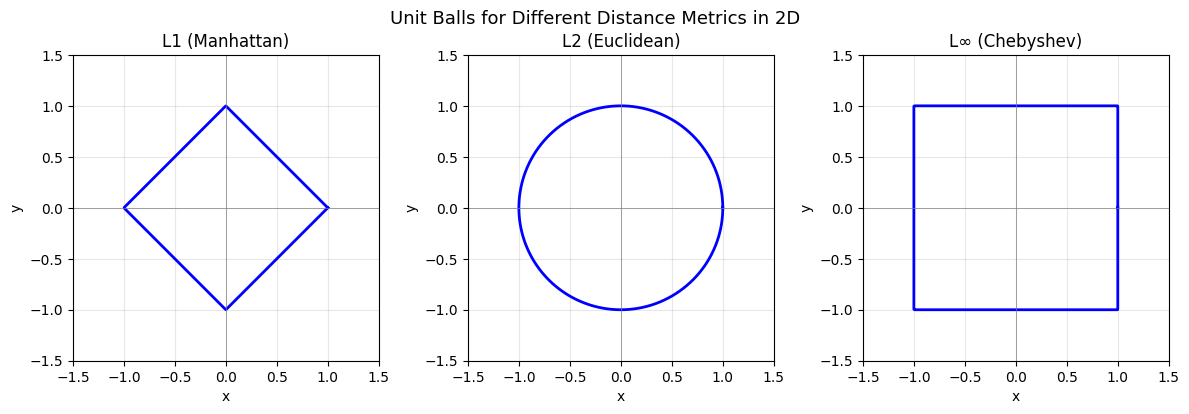

In [4]:
theta = np.linspace(0, 2 * np.pi, 1000)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

configs = [
    ('L1 (Manhattan)',  lambda x, y: np.abs(x) + np.abs(y)),
    ('L2 (Euclidean)',  lambda x, y: np.sqrt(x**2 + y**2)),
    ('L∞ (Chebyshev)',  lambda x, y: np.maximum(np.abs(x), np.abs(y))),
]

for ax, (title, dist_fn) in zip(axes, configs):
    # Sample unit circle in polar, project back to x/y
    xs = np.cos(theta)
    ys = np.sin(theta)
    scale = dist_fn(xs, ys)
    xs_unit = xs / scale
    ys_unit = ys / scale

    ax.plot(xs_unit, ys_unit, 'b-', linewidth=2)
    ax.set_aspect('equal')
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)
    ax.set_title(title)
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('x')
    ax.set_ylabel('y')

plt.suptitle('Unit Balls for Different Distance Metrics in 2D', fontsize=13)
plt.tight_layout()
plt.show()

<a id="find-knn"></a>
## 6. Finding the K Nearest Neighbors

Given precomputed distances, we use `np.argsort` to rank training points by distance to the query, then take the first K indices. We verify on a tiny 5-point dataset.

In [5]:
def get_k_neighbors(X_train, y_train, x_query, k, metric='euclidean', p=2):
    """
    Return indices, distances, and labels of the K nearest neighbors of x_query.
    
    Args:
        X_train : (n, m) training feature matrix
        y_train : (n,)  training labels / values
        x_query : (m,)  single query point
        k       : number of neighbors
        metric  : 'euclidean', 'manhattan', 'minkowski', 'cosine'
        p       : order for Minkowski metric
    
    Returns:
        indices   : (k,) indices into X_train
        distances : (k,) corresponding distances
        labels    : (k,) corresponding labels
    """
    dists   = pairwise_distances(x_query.reshape(1, -1), X_train, metric=metric, p=p)[0]
    sorted_idx = np.argsort(dists)
    indices    = sorted_idx[:k]
    return indices, dists[indices], y_train[indices]


# Quick test
X_toy = np.array([[1.0, 1.0], [2.0, 1.5], [3.0, 3.0], [5.0, 4.0], [6.0, 5.0]])
y_toy = np.array([0, 0, 1, 1, 1])
query = np.array([2.5, 2.0])

idx, dists, labels = get_k_neighbors(X_toy, y_toy, query, k=3)
print("Query point:", query)
for i, (d, lab) in enumerate(zip(dists, labels)):
    print(f"  Neighbor {i+1}: point {X_toy[idx[i]]}  dist={d:.3f}  label={lab}")

Query point: [2.5 2. ]
  Neighbor 1: point [2.  1.5]  dist=0.707  label=0
  Neighbor 2: point [3. 3.]  dist=1.118  label=1
  Neighbor 3: point [1. 1.]  dist=1.803  label=0


<a id="classification-vote"></a>
## 7. Classification: Majority Vote

Once we have the K nearest labels, we pick the most frequent one. In case of ties, we return the class with the smaller label (consistent with sklearn's behavior).

In [6]:
def majority_vote(labels):
    """
    Return the most common label. Ties broken by smallest label value.
    """
    counts = Counter(labels)
    return max(counts, key=lambda c: (counts[c], -c))


# Examples
print(majority_vote([0, 0, 1]))       # → 0  (clear majority)
print(majority_vote([0, 1, 1]))       # → 1
print(majority_vote([0, 1, 2, 1]))    # → 1

0
1
1


<a id="regression-mean"></a>
## 8. Regression: Mean of Neighbors

For regression, the prediction is the arithmetic mean of the K neighbors' target values.

In [7]:
def neighbor_mean(values):
    """Mean of neighbor target values for regression."""
    return np.mean(values)


print(neighbor_mean([2.5, 3.0, 2.8]))   # → ~2.767
print(neighbor_mean([10.0, 20.0]))       # → 15.0

2.766666666666667
15.0


<a id="weighted-knn"></a>
## 9. Weighted KNN

Standard KNN gives equal weight to all K neighbors. But a neighbor at distance 0.01 should be far more influential than one at distance 10.

**Inverse-distance weighting:**

$$\hat{y} = \frac{\sum_{i \in \mathcal{N}_K} w_i \cdot y_i}{\sum_{i \in \mathcal{N}_K} w_i}, \quad w_i = \frac{1}{d(\mathbf{x}_q, \mathbf{x}_i) + \varepsilon}$$

The $\varepsilon$ (small constant) avoids division by zero when a test point exactly coincides with a training point.

For classification, the same weights replace the vote count:

$$\hat{y} = \underset{c}{\arg\max} \sum_{i \in \mathcal{N}_K} w_i \cdot \mathbf{1}[y_i = c]$$

In [ ]:
def weighted_majority_vote(labels, distances, eps=1e-10):
    """Inverse-distance weighted majority vote."""
    weights = 1.0 / (distances + eps)
    class_weights = {}
    for label, w in zip(labels, weights):
        class_weights[label] = class_weights.get(label, 0.0) + w
    return max(class_weights, key=class_weights.get)


def weighted_mean(values, distances, eps=1e-10):
    """Inverse-distance weighted mean for regression."""
    weights = 1.0 / (distances + eps)
    return np.dot(weights, values) / weights.sum()


# Compare uniform vs weighted: neighbor at distance 0.1 vs 10.0
labels_ex = np.array([0, 0, 1])    # two class-0 but one is very far
dists_ex  = np.array([0.1, 10.0, 0.2])  # class-1 neighbor is actually very close

print("Uniform vote:",   majority_vote(labels_ex))             # → 0 (2 vs 1)
print("Weighted vote:",  weighted_majority_vote(labels_ex, dists_ex))  # → 0 (class 0 wins: weight 10.1 vs 5.0)

<a id="implementation"></a>
## 10. Complete KNN Implementation

We assemble all components into a sklearn-style `KNN` class supporting classification and regression, uniform and weighted voting, and any distance metric defined above.

The `KNN` class stores the training data at `fit` time (no computation). At `predict` time it calls `pairwise_distances` (vectorized), sorts, and aggregates with the appropriate function based on `task` and `weights`.

In [9]:
class KNN:
    """
    K-Nearest Neighbors for classification and regression.

    Parameters
    ----------
    k       : int   — number of neighbors
    task    : 'classification' or 'regression'
    metric  : 'euclidean', 'manhattan', 'minkowski', 'cosine'
    p       : int   — Minkowski order (only used when metric='minkowski')
    weights : 'uniform' or 'distance'
    """

    def __init__(self, k=5, task='classification',
                 metric='euclidean', p=2, weights='uniform'):
        self.k       = k
        self.task    = task
        self.metric  = metric
        self.p       = p
        self.weights = weights

    def fit(self, X, y):
        """Store training data. No computation performed."""
        self.X_train_ = np.array(X, dtype=float)
        self.y_train_ = np.array(y)
        self.n_samples_, self.n_features_ = self.X_train_.shape
        return self

    def predict(self, X):
        """Predict labels (classification) or values (regression) for each row of X."""
        X = np.array(X, dtype=float)
        # Vectorized: compute all distances at once — shape (n_query, n_train)
        dist_matrix = pairwise_distances(X, self.X_train_,
                                         metric=self.metric, p=self.p)
        predictions = []
        for i in range(len(X)):
            dists      = dist_matrix[i]
            sorted_idx = np.argsort(dists)[:self.k]
            k_dists    = dists[sorted_idx]
            k_labels   = self.y_train_[sorted_idx]
            predictions.append(self._aggregate(k_labels, k_dists))
        return np.array(predictions)

    def _aggregate(self, labels, dists):
        if self.task == 'classification':
            if self.weights == 'distance':
                return weighted_majority_vote(labels, dists)
            return majority_vote(labels)
        else:  # regression
            if self.weights == 'distance':
                return weighted_mean(labels.astype(float), dists)
            return neighbor_mean(labels.astype(float))


print("KNN class defined.")

KNN class defined.


<a id="classification-demo"></a>
## 11. Demo: Classification (Iris Dataset)

We test our implementation on the Iris dataset (150 samples, 4 features, 3 classes) and compare accuracy against sklearn's `KNeighborsClassifier`.

Load Iris, split 80/20, and evaluate our KNN at $K \in \{1, 3, 5, 7, 9\}$ with both Euclidean and Manhattan distance. Side-by-side with sklearn for validation.

In [10]:
iris = load_iris()
X_iris, y_iris = iris.data, iris.target
X_tr, X_te, y_tr, y_te = train_test_split(X_iris, y_iris,
                                           test_size=0.2, random_state=42)
print(f"Train: {X_tr.shape[0]}  Test: {X_te.shape[0]}")
print(f"Features: {iris.feature_names}")
print(f"Classes:  {iris.target_names}")

Train: 120  Test: 30
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes:  ['setosa' 'versicolor' 'virginica']


We sweep $K$ from 1 to 9 (odd values to avoid ties) and compare our implementation against sklearn for two metrics.

In [11]:
print(f"{'K':>3}  {'metric':>12}  {'Ours':>8}  {'sklearn':>8}")
print("-" * 40)

for k in [1, 3, 5, 7, 9]:
    for metric, sk_metric in [('euclidean', 'euclidean'), ('manhattan', 'manhattan')]:
        ours = KNN(k=k, metric=metric)
        ours.fit(X_tr, y_tr)
        acc_ours = accuracy_score(y_te, ours.predict(X_te))

        sk = KNeighborsClassifier(n_neighbors=k, metric=sk_metric, weights='uniform')
        sk.fit(X_tr, y_tr)
        acc_sk = accuracy_score(y_te, sk.predict(X_te))

        print(f"{k:>3}  {metric:>12}  {acc_ours:>8.4f}  {acc_sk:>8.4f}")

  K        metric      Ours   sklearn
----------------------------------------
  1     euclidean    1.0000    1.0000
  1     manhattan    1.0000    1.0000
  3     euclidean    1.0000    1.0000
  3     manhattan    1.0000    1.0000
  5     euclidean    1.0000    1.0000
  5     manhattan    1.0000    1.0000
  7     euclidean    0.9667    0.9667
  7     manhattan    1.0000    1.0000
  9     euclidean    1.0000    1.0000
  9     manhattan    0.9667    0.9667


<a id="decision-boundary"></a>
## 12. Visualizing Decision Boundaries

Using 2 features lets us plot the Voronoi-like regions KNN assigns to each class. Unlike decision trees (axis-aligned splits), KNN boundaries can be arbitrarily curved.

`plot_knn_boundary` creates a dense meshgrid over the 2D feature space, calls `knn.predict` on every grid point, and colors the regions by predicted class. Training points are overlaid on top.

In [12]:
def plot_knn_boundary(knn, X, y, title='KNN Decision Boundary',
                      xlabel='Feature 1', ylabel='Feature 2', h=0.05):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                          np.arange(y_min, y_max, h))

    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    cmap_bg     = plt.cm.Pastel1
    cmap_points = plt.cm.Set1
    n_classes   = len(np.unique(y))

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.contourf(xx, yy, Z, alpha=0.4, cmap=cmap_bg,
                levels=np.arange(-0.5, n_classes + 0.5, 1))

    for cls in np.unique(y):
        mask = y == cls
        ax.scatter(X[mask, 0], X[mask, 1],
                   c=[cmap_points(cls / n_classes)],
                   label=f'Class {cls}', edgecolors='k',
                   linewidth=0.5, s=50)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()

We use the two petal features (most discriminative) and compare boundaries for $K \in \{1, 5, 25\}$ to visualize underfitting, good fit, and over-smoothing.

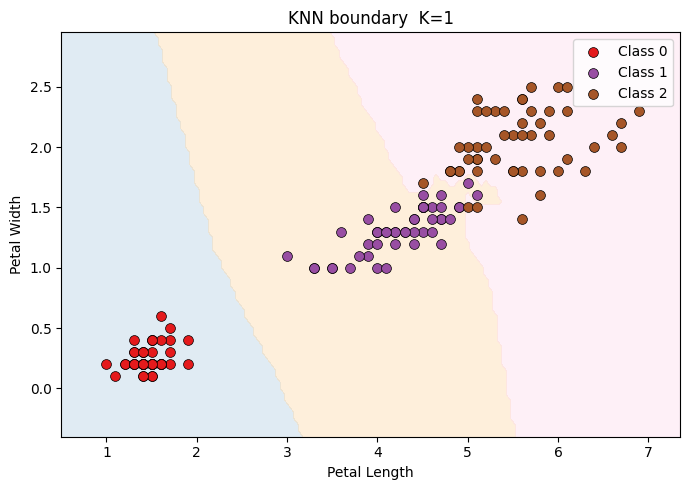

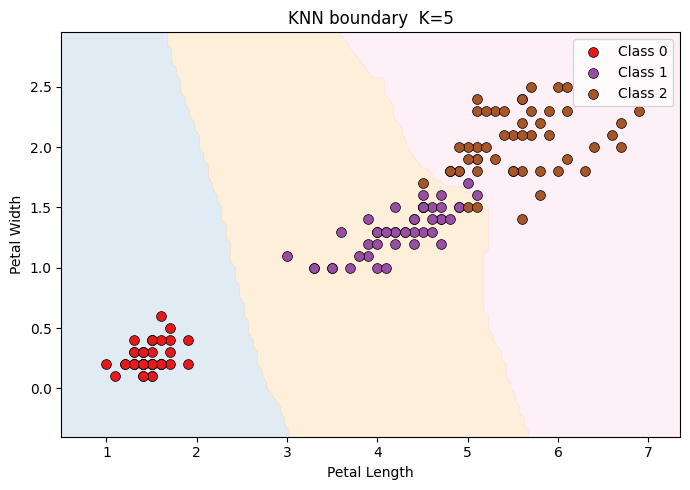

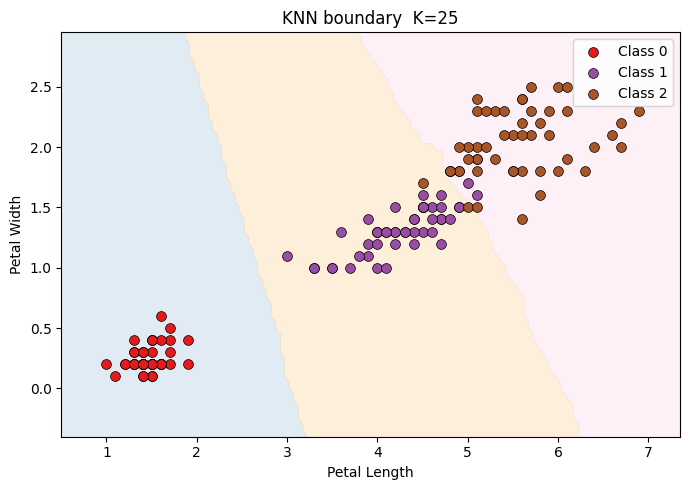

In [13]:
X_2d = X_iris[:, 2:]  # petal length, petal width

for k in [1, 5, 25]:
    knn_2d = KNN(k=k, task='classification', metric='euclidean')
    knn_2d.fit(X_2d, y_iris)
    plot_knn_boundary(
        knn_2d, X_2d, y_iris,
        title=f'KNN boundary  K={k}',
        xlabel='Petal Length', ylabel='Petal Width'
    )

<a id="choosing-k"></a>
## 13. Choosing K: Bias-Variance Tradeoff

K is the most important hyperparameter of KNN. It directly controls the **bias-variance tradeoff**:

- **Small K** (e.g., K=1): model is very sensitive to individual training points → high variance, low bias, tends to overfit.
- **Large K** (e.g., K=n): averages over entire dataset → high bias, low variance, tends to underfit.

The optimal K balances these two effects. Since there is no closed-form solution, we use **cross-validation** to select K.

We sweep K from 1 to 40 on the Iris dataset, recording 5-fold cross-validation accuracy at each value. We plot both train and CV accuracy to see the classic U-shaped test error curve.

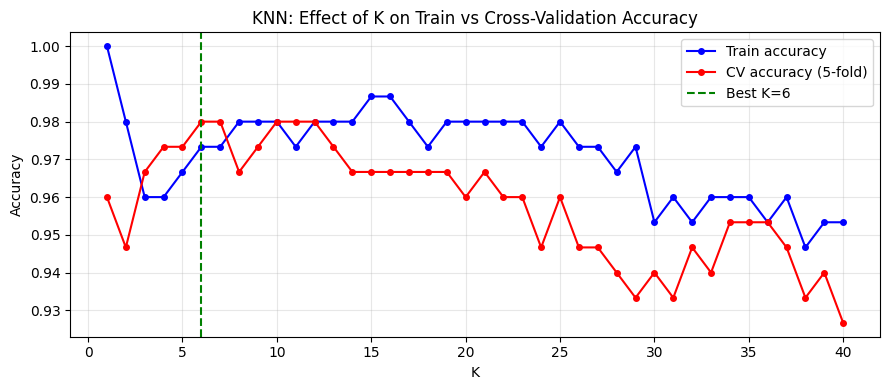

Best K = 6  (CV accuracy = 0.9800)
Train accuracy at best K = 0.9733


In [14]:
k_range     = range(1, 41)
cv_accs     = []
train_accs  = []

for k in k_range:
    # sklearn for fast CV sweep (our class matches it exactly)
    sk = KNeighborsClassifier(n_neighbors=k)
    cv_score = cross_val_score(sk, X_iris, y_iris, cv=5, scoring='accuracy').mean()
    cv_accs.append(cv_score)

    sk.fit(X_iris, y_iris)
    train_accs.append(accuracy_score(y_iris, sk.predict(X_iris)))

best_k  = list(k_range)[np.argmax(cv_accs)]

plt.figure(figsize=(9, 4))
plt.plot(k_range, train_accs, 'b-o', markersize=4, label='Train accuracy')
plt.plot(k_range, cv_accs,    'r-o', markersize=4, label='CV accuracy (5-fold)')
plt.axvline(best_k, color='green', linestyle='--', label=f'Best K={best_k}')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.title('KNN: Effect of K on Train vs Cross-Validation Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Best K = {best_k}  (CV accuracy = {max(cv_accs):.4f})")
print(f"Train accuracy at best K = {train_accs[best_k - 1]:.4f}")

<a id="scaling"></a>
## 14. Feature Scaling: Why It Matters

KNN uses raw distances. If one feature ranges in $[0, 1000]$ and another in $[0, 1]$, the first feature **dominates the distance computation entirely** — the second feature is effectively ignored.

**Solution:** standardize features before computing distances.

$$x_j' = \frac{x_j - \mu_j}{\sigma_j}$$

After standardization all features have mean 0 and standard deviation 1, so each contributes equally to the distance.

We construct a synthetic dataset where one feature is on a scale 1000× larger than the other. We compare KNN accuracy with and without standardization to demonstrate the effect of scale.

In [15]:
# Dataset: feature 0 in [0,1], feature 1 in [0,1000]
X_raw, y_scale = make_classification(n_samples=300, n_features=2,
                                      n_informative=2, n_redundant=0,
                                      random_state=0)
X_raw[:, 1] *= 1000  # inflate feature 1

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

X_tr_r, X_te_r, y_tr_s, y_te_s = train_test_split(X_raw,    y_scale, test_size=0.3, random_state=42)
X_tr_s, X_te_s, _,      _      = train_test_split(X_scaled, y_scale, test_size=0.3, random_state=42)

k = 7
knn_raw    = KNN(k=k); knn_raw.fit(X_tr_r, y_tr_s)
knn_scaled = KNN(k=k); knn_scaled.fit(X_tr_s, y_tr_s)

acc_raw    = accuracy_score(y_te_s, knn_raw.predict(X_te_r))
acc_scaled = accuracy_score(y_te_s, knn_scaled.predict(X_te_s))

print(f"KNN K={k} WITHOUT scaling: accuracy = {acc_raw:.4f}")
print(f"KNN K={k} WITH    scaling: accuracy = {acc_scaled:.4f}")
print(f"Improvement: {acc_scaled - acc_raw:+.4f}")

KNN K=7 WITHOUT scaling: accuracy = 0.9333
KNN K=7 WITH    scaling: accuracy = 0.9556
Improvement: +0.0222


<a id="regression-demo"></a>
## 15. Demo: Regression

KNN regression approximates a function by averaging the K nearest training values. The result is a **piecewise-constant** function (uniform weights) or a **locally weighted average** (distance weights).

We fit KNN regressors at three values of $K$ on a noisy sine curve and compare RMSE. Then we compare uniform vs distance-weighted KNN at the best K.

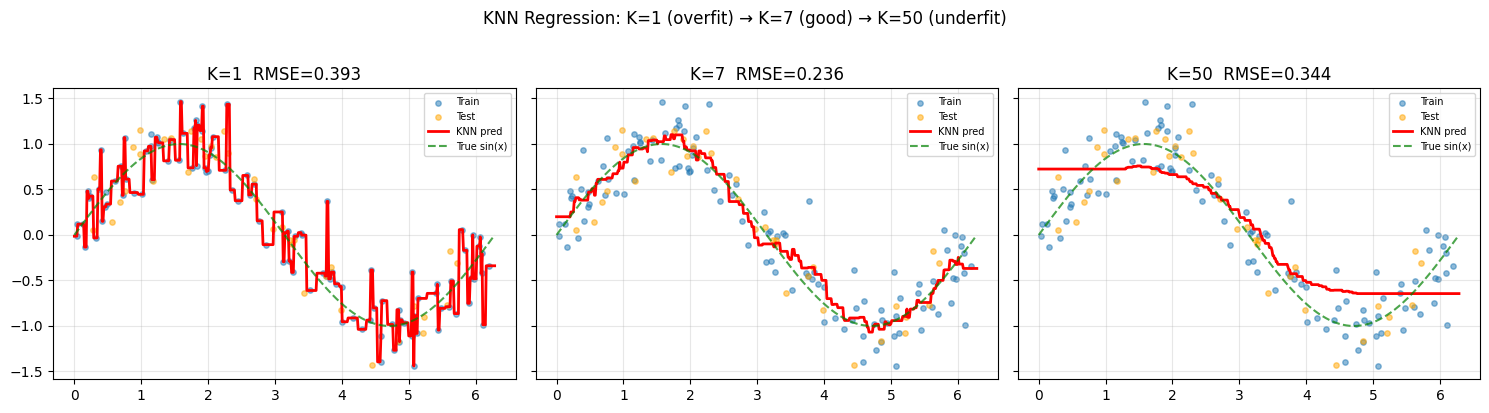

K=7  Uniform RMSE:  0.2362
K=7  Weighted RMSE: 0.2902


In [16]:
X_reg = np.sort(np.random.uniform(0, 2 * np.pi, 150)).reshape(-1, 1)
y_reg = np.sin(X_reg.ravel()) + np.random.normal(0, 0.25, 150)

X_tr_r2, X_te_r2, y_tr_r2, y_te_r2 = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=0)

X_plot = np.linspace(0, 2 * np.pi, 500).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, k in zip(axes, [1, 7, 50]):
    knn_r = KNN(k=k, task='regression', metric='euclidean')
    knn_r.fit(X_tr_r2, y_tr_r2)
    y_pred   = knn_r.predict(X_plot)
    rmse     = np.sqrt(mean_squared_error(y_te_r2, knn_r.predict(X_te_r2)))

    ax.scatter(X_tr_r2, y_tr_r2, s=15, alpha=0.5, label='Train')
    ax.scatter(X_te_r2, y_te_r2, s=15, alpha=0.5, c='orange', label='Test')
    ax.plot(X_plot, y_pred, 'r-', linewidth=2, label='KNN pred')
    ax.plot(X_plot, np.sin(X_plot), 'g--', linewidth=1.5, alpha=0.7, label='True sin(x)')
    ax.set_title(f'K={k}  RMSE={rmse:.3f}')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.suptitle('KNN Regression: K=1 (overfit) → K=7 (good) → K=50 (underfit)', y=1.02)
plt.tight_layout()
plt.show()

# Uniform vs weighted at K=7
knn_unif = KNN(k=7, task='regression', weights='uniform')
knn_wght = KNN(k=7, task='regression', weights='distance')
knn_unif.fit(X_tr_r2, y_tr_r2)
knn_wght.fit(X_tr_r2, y_tr_r2)

rmse_u = np.sqrt(mean_squared_error(y_te_r2, knn_unif.predict(X_te_r2)))
rmse_w = np.sqrt(mean_squared_error(y_te_r2, knn_wght.predict(X_te_r2)))
print(f"K=7  Uniform RMSE:  {rmse_u:.4f}")
print(f"K=7  Weighted RMSE: {rmse_w:.4f}")

<a id="curse"></a>
## 16. Curse of Dimensionality

KNN fundamentally relies on the idea that nearby points in feature space are similar. In **high dimensions**, this intuition breaks down.

### The Empty Space Phenomenon

Consider a hypercube $[0,1]^d$. To capture a fraction $f$ of the total volume using a smaller hypercube centered at a point, we need a side length:

$$l = f^{1/d}$$

For $f = 0.01$ (1% of data) and $d = 10$: $l = 0.01^{0.1} \approx 0.63$. We need to extend **63% of the range in each dimension** just to capture 1% of the data.

### Distance Concentration

In high dimensions, the ratio of the maximum to minimum distance from a query point to training points converges to 1 in probability (Beyer et al., 1999):

$$\lim_{d \to \infty} \frac{\max_i d(\mathbf{x}_q, \mathbf{x}_i) - \min_i d(\mathbf{x}_q, \mathbf{x}_i)}{\min_i d(\mathbf{x}_q, \mathbf{x}_i)} = 0$$

When all distances become equal, "nearest" neighbors are no more similar than random points — KNN loses its discriminative power.

**Mitigations:**
- Use dimensionality reduction (PCA, UMAP) before KNN
- Use Manhattan distance instead of Euclidean (less affected)
- Switch to cosine distance for high-dimensional sparse data
- Use a model that scales better with dimensions (SVM, tree-based)

We empirically demonstrate distance concentration: for increasing dimensionality $d$, we compute the ratio $(d_{max} - d_{min}) / d_{min}$ for a fixed query point and 500 random training points. The ratio shrinks toward zero as $d$ grows.

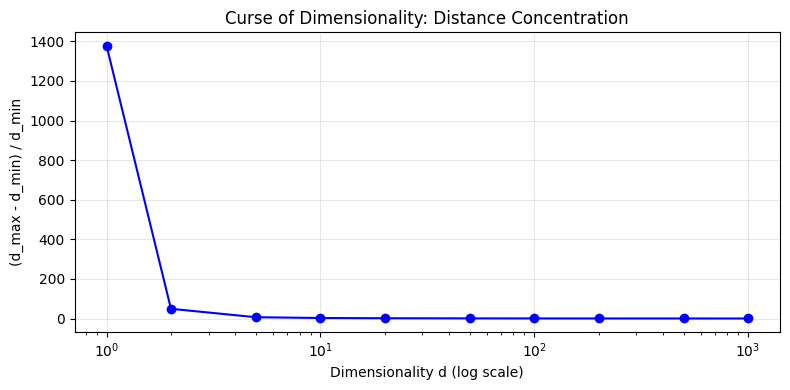

As d grows, all distances become nearly equal → KNN neighbors lose meaning.


In [17]:
dims     = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
n_points = 500
ratios   = []

for d in dims:
    X_rand = np.random.uniform(0, 1, (n_points, d))
    query  = np.random.uniform(0, 1, (1, d))
    dists  = pairwise_distances(query, X_rand, metric='euclidean')[0]
    ratio  = (dists.max() - dists.min()) / (dists.min() + 1e-15)
    ratios.append(ratio)

plt.figure(figsize=(8, 4))
plt.semilogx(dims, ratios, 'b-o', markersize=6)
plt.xlabel('Dimensionality d (log scale)')
plt.ylabel('(d_max - d_min) / d_min')
plt.title('Curse of Dimensionality: Distance Concentration')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("As d grows, all distances become nearly equal → KNN neighbors lose meaning.")

<a id="complexity"></a>
## 17. Complexity Analysis

| Phase | Brute-force | KD-Tree (sklearn) | Notes |
|---|---|---|---|
| **Training** | $O(1)$ | $O(n \log n)$ | KD-tree builds an index |
| **Prediction (single)** | $O(np)$ | $O(p \log n)$ | $p$ = features |
| **Prediction (batch $q$ queries)** | $O(qnp)$ | $O(qp \log n)$ | KD-tree degrades at $p > 20$ |
| **Space** | $O(np)$ | $O(np)$ | Entire training set stored |

**Key trade-offs:**
- Brute-force is fine for small datasets ($n < 10^4$)
- KD-tree or Ball-tree (sklearn default) speeds up prediction at low-medium dimensions
- At high $d$ ($d > 20$), spatial indexing loses its advantage and brute-force is competitive

**Compared to other algorithms:**

| Algorithm | Train time | Predict time | Memory |
|---|---|---|---|
| KNN | $O(1)$ | $O(np)$ | $O(np)$ (all data) |
| Decision Tree | $O(np \log n)$ | $O(\log n)$ | $O(n)$ |
| SVM | $O(n^2 p)$ to $O(n^3)$ | $O(s_v \cdot p)$ | $O(s_v)$ ($s_v$ = support vectors) |
| Logistic Reg | $O(np)$ per iteration | $O(p)$ | $O(p)$ |

<a id="pros-cons"></a>
## 18. Advantages and Disadvantages

### Advantages

| Property | Detail |
|---|---|
| **Trivial to implement** | No math beyond distance computation |
| **Non-parametric** | No assumptions about data distribution |
| **Naturally multi-class** | No one-vs-rest needed; vote over all classes directly |
| **Adapts locally** | Decision boundary shaped entirely by local data density |
| **Zero training time** | Adding new training points requires no retraining |
| **Interpretable predictions** | Can always show user the K nearest neighbors as explanation |

### Disadvantages

| Property | Detail |
|---|---|
| **Slow at inference** | $O(np)$ per prediction — scales badly with large $n$ |
| **Memory intensive** | Entire training set must be stored and accessible |
| **Feature scaling required** | Sensitive to scale and irrelevant features |
| **Curse of dimensionality** | Breaks down at high $d$; distances lose meaning |
| **No feature importance** | Cannot tell you which features matter |
| **Imbalanced classes** | Majority class dominates; need weighted voting or resampling |

<a id="summary"></a>
## 19. Summary

What we built, step by step:

```
1. Distance metrics
   ├── Euclidean:  d(u,v) = √Σ(uⱼ - vⱼ)²
   ├── Manhattan:  d(u,v) = Σ|uⱼ - vⱼ|
   ├── Minkowski:  d(u,v) = (Σ|uⱼ - vⱼ|ᵖ)^(1/p)
   └── Cosine:     d(u,v) = 1 - (u·v)/(‖u‖‖v‖)

2. K nearest neighbors
   Sort distances → take first K indices

3. Aggregation
   ├── Classification: majority vote (or weighted by 1/distance)
   └── Regression:     mean (or weighted by 1/distance)

4. Key hyperparameter: K
   Small K = low bias, high variance (overfit)
   Large K = high bias, low variance (underfit)
   Optimal K via cross-validation

5. Feature scaling mandatory before distance computation

6. Curse of dimensionality degrades KNN at d >> 20
```

KNN is the baseline to beat in low-to-medium dimension tabular problems. Its simplicity makes it a useful sanity check before reaching for complex models.

<a id="sources"></a>
## 20. Sources

### Foundational Papers
- **Fix, E., & Hodges, J.L. (1951)**. Discriminatory analysis — nonparametric discrimination: consistency properties. *USAF School of Aviation Medicine Technical Report*. — Original KNN proposal.
- **Cover, T., & Hart, P. (1967)**. Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21–27. [DOI](https://doi.org/10.1109/TIT.1967.1053964) — Proved 1-NN error is asymptotically at most twice the Bayes error rate.
- **Bellman, R. (1957)**. *Dynamic Programming*. Princeton University Press. — Introduced the "curse of dimensionality" term.
- **Beyer, K., Goldstein, J., Ramakrishnan, R. & Shaft, U. (1999)**. When is "Nearest Neighbor" Meaningful? *ICDT*. [Link](https://link.springer.com/chapter/10.1007/3-540-49257-7_15) — Formal treatment of distance concentration.

### Textbooks
- James, Witten, Hastie, Tibshirani. ***An Introduction to Statistical Learning***. Chapter 2 & 4. [Free PDF](https://www.statlearning.com/)
- Hastie, Tibshirani, Friedman. ***The Elements of Statistical Learning***. Chapter 13. [Free PDF](https://web.stanford.edu/~hastie/ElemStatLearn/)
- Bishop, C.M. ***Pattern Recognition and Machine Learning***. Chapter 2.

### Online Resources
- [scikit-learn — Nearest Neighbors](https://scikit-learn.org/stable/modules/neighbors.html)
- [Wikipedia — k-nearest neighbors algorithm](https://en.wikipedia.org/wiki/K-nearest_neighbors_algorithm)
- [Wikipedia — Curse of dimensionality](https://en.wikipedia.org/wiki/Curse_of_dimensionality)